# siann quickstart

siann is fast similarity search on Apple silicon for dense vectors. Give it base vectors and a metric, and
it finds each query's nearest neighbors, on the GPU or the CPU (BLAS through NumPy, and siann's own Rust
kernels), choosing the device for each search unless you tell it which.

This notebook covers what each metric means and how to choose one, the scores siann returns and how it
explains its choices, how the GPU and the CPU compare as batches grow, tuning siann's routing to your own
data and hardware, exact search as the ground truth, and approximate search to a recall target.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np

import siann

siann.__version__

'0.2.0'

## The metrics, in two dimensions

siann searches by five measures of nearness. In two dimensions they are easy to see: below, 600 points,
one query (the orange dot), and each metric's 25 nearest points to it (blue), with the boundary that encloses them.
The L2, L1 and L-infinity panels are zoomed in on the query; the cosine and inner product panels show the
whole cloud, since their regions run out from the origin.

- [**L2**](https://en.wikipedia.org/wiki/Euclidean_distance) (Euclidean) is straight-line distance; its ball is a circle. The usual
  choice for vectors whose coordinates are comparable measurements.
- [**L1**](https://en.wikipedia.org/wiki/Taxicab_geometry) (Manhattan) adds up the coordinate differences; its ball is a diamond. One
  large difference counts less than under L2, which squares it, so L1 is more robust to a few outlying
  coordinates.
- [**L-infinity**](https://en.wikipedia.org/wiki/Chebyshev_distance) (Chebyshev) is the largest single coordinate difference; its ball
  is a square. A neighbor within distance r differs by at most r in every coordinate: a worst-case bound.
- [**Cosine**](https://en.wikipedia.org/wiki/Cosine_similarity) compares directions only, so its neighbors fill a wedge from the origin,
  whatever their length. The usual choice for text and image embeddings.
- [**Inner product**](https://en.wikipedia.org/wiki/Dot_product) favors vectors that point the query's way *and* are long: its
  neighbors lie beyond a line perpendicular to the query. For embeddings trained to be compared this way.

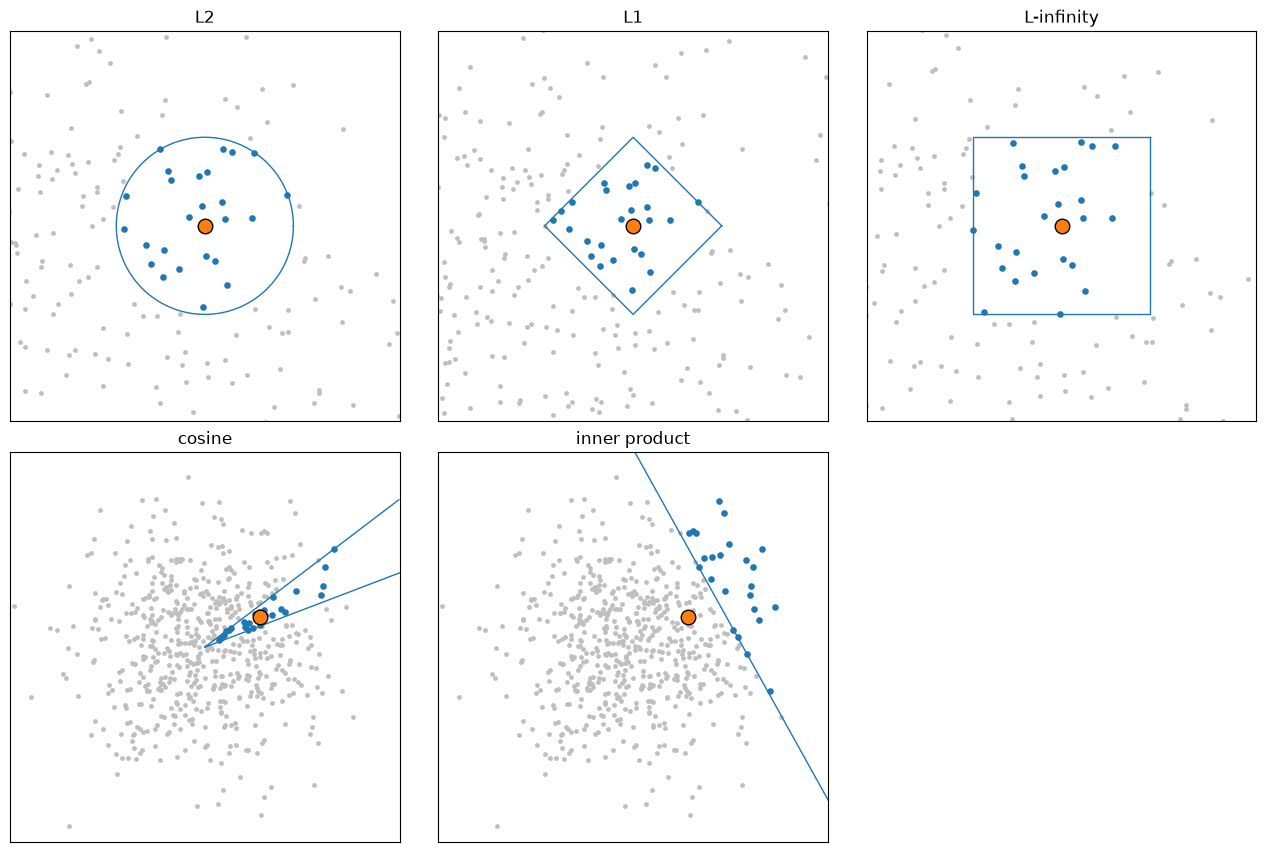

In [2]:
rng = np.random.default_rng(1)
pts = rng.standard_normal((600, 2), dtype=np.float32)
q = np.array([[0.9, 0.5]], dtype=np.float32)
k = 25

fig, axes = plt.subplots(2, 3, figsize=(13, 8.6))
axes = axes.ravel()
axes[-1].axis("off")
for ax, metric in zip(axes, siann.METRICS):
    res = siann.Index(pts, metric, device="cpu").search(q, k)
    near, kth = res.indices[0], res.scores[0, -1]
    ax.scatter(*pts.T, s=6, c="0.75")
    ax.scatter(*pts[near].T, s=14, c="tab:blue")
    ax.scatter(*q.T, s=110, c="tab:orange", edgecolors="black", linewidths=1, zorder=3)
    t = np.linspace(0, 2 * np.pi, 400)
    if metric == "l2":
        ax.plot(q[0, 0] + kth * np.cos(t), q[0, 1] + kth * np.sin(t), c="tab:blue", lw=1)
    elif metric == "l1":
        ax.plot(q[0, 0] + kth * np.array([1, 0, -1, 0, 1]), q[0, 1] + kth * np.array([0, 1, 0, -1, 0]), c="tab:blue", lw=1)
    elif metric == "linf":
        ax.plot(q[0, 0] + kth * np.array([1, -1, -1, 1, 1]), q[0, 1] + kth * np.array([1, 1, -1, -1, 1]), c="tab:blue", lw=1)
    elif metric == "cosine":
        a, w = np.arctan2(q[0, 1], q[0, 0]), np.arccos(np.clip(kth, -1, 1))
        for b in (a - w, a + w):
            ax.plot([0, 4 * np.cos(b)], [0, 4 * np.sin(b)], c="tab:blue", lw=1)
    else:   # the line q.x = kth, perpendicular to q
        u = q[0] / np.linalg.norm(q[0])
        base, along = u * kth / np.linalg.norm(q[0]), np.array([-u[1], u[0]])
        ax.plot(*np.array([base - 5 * along, base + 5 * along]).T, c="tab:blue", lw=1)
    ax.set_title({"l2": "L2", "l1": "L1", "linf": "L-infinity", "cosine": "cosine", "ip": "inner product"}[metric])
    # the balls are small: zoom on the query; cosine and inner product regions run out from the origin
    span = 2.2 * kth if metric in ("l2", "l1", "linf") else 3.2
    cx, cy = (q[0] if metric in ("l2", "l1", "linf") else (0, 0))
    ax.set_xlim(cx - span, cx + span); ax.set_ylim(cy - span, cy + span)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout()

## Some vectors

Real embeddings cluster, so instead of uniform noise the rest of the notebook uses 200,000 points in 128
dimensions drawn around 1,000 random centers, and up to 10,000 queries drawn the same way.

In [3]:
centers = rng.standard_normal((1000, 128), dtype=np.float32)


def sample(n):
    return (centers[rng.integers(0, len(centers), n)]
            + 0.3 * rng.standard_normal((n, 128), dtype=np.float32))


xb, xq = sample(200_000), sample(10_000)
xb.shape, xq.shape

((200000, 128), (10000, 128))

## Exact search

`siann.Index(xb, metric)` builds an index, and `index.search(xq, k)` returns each query's `k` nearest base
vectors, best first: `indices` (int64) and `scores`. Without a recall target the search is exact, so these
are the true nearest neighbors.

In [4]:
index = siann.Index(xb, metric="cosine")
res = index.search(xq[:1000], k=5)
res.indices[:3], res.scores[:3]

(array([[141620,  32881,  99292,  30736, 181940],
        [165465, 119464, 126810, 167009, 169820],
        [ 48693,  77403, 184436, 156066, 148656]]),
 array([[0.94919854, 0.9488592 , 0.94846785, 0.94697994, 0.9468435 ],
        [0.9333264 , 0.93145066, 0.9305314 , 0.9304897 , 0.9302278 ],
        [0.9436814 , 0.94351155, 0.93700975, 0.93628126, 0.93586385]],
       dtype=float32))

`index.plan` says what was chosen and why: here, how a search is routed to the GPU or the CPU by its batch
size, under which profile, and how each device computes it.

In [5]:
print(index.plan)

siann.Index: 200,000 vectors, 128 dimensions, metric cosine
  kind: exact
  device: auto
  exact search (no recall target): the results are the true nearest neighbors
  GPU found: always on the GPU (profile: siann's default, tuned on an Apple M3 Max with about a million vectors)
  on the CPU: a BLAS matrix multiply through NumPy and siann's Rust top-k
  cosine: vectors normalized to unit length and ranked by inner product


## Scores

Scores are each metric's natural value: the distance for L2 (not squared), L1 and L-infinity, smallest
first, and the similarity for cosine and inner product, largest first. They are exact: here they are
recomputed with NumPy for an L2 search. The metrics also disagree about who is nearest, even on the same
data: the share of each L2 top 10 that another metric's top 10 shares is below.

In [6]:
l2 = siann.Index(xb, "l2").search(xq[:1000], k=10)
print("L2 scores exact:", np.allclose(l2.scores, np.linalg.norm(xb[l2.indices] - xq[:1000, None, :], axis=2), rtol=1e-4))
for metric in ("l1", "linf", "cosine", "ip"):
    other = siann.Index(xb, metric).search(xq[:1000], k=10).indices
    shared = np.mean([len(set(a) & set(b)) / 10 for a, b in zip(l2.indices, other)])
    print(f"{metric:7s} shares {shared:.0%} of L2's top 10")

L2 scores exact: True
l1      shares 68% of L2's top 10
linf    shares 25% of L2's top 10
cosine  shares 82% of L2's top 10
ip      shares 10% of L2's top 10


## The GPU and the CPU, by batch size

`device="cpu"` or `device="gpu"` pins an index to one device, and the same argument to `search` overrides it
for one call; each device makes its own copy of the vectors the first time a search needs it. Both return
the same neighbors. Which is faster depends on the batch and the metric: a GPU call has a fixed cost that a
large batch spreads thin, and L2, cosine and inner product are matrix multiplies on either device, where
L1 and L-infinity have no matrix-multiply form, so the GPU's lead is largest there.

Below, queries per second on this machine at batch sizes from 1 to 10,000, k = 10. Each point is the
second of two identical calls: the first builds the device's copy and, on the GPU, compiles the kernels for
that batch size.

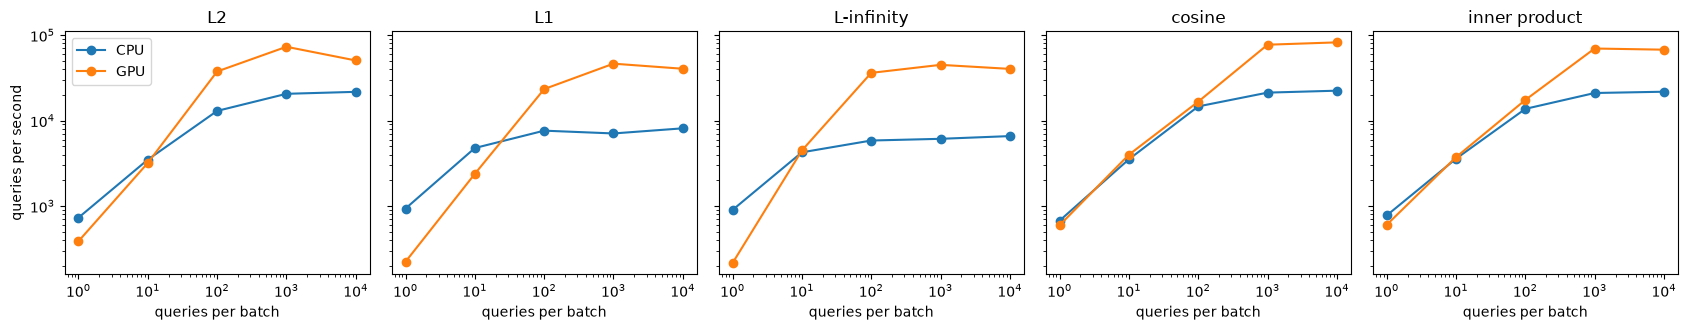

In [7]:
devices = ["cpu", "gpu"] if siann.gpu_available() else ["cpu"]
batches = [1, 10, 100, 1000, 10_000]
rate = {}
for metric in siann.METRICS:
    idx = siann.Index(xb, metric)
    for device in devices:
        for b in batches:
            idx.search(xq[:b], 10, device=device)
            start = time.perf_counter()
            idx.search(xq[:b], 10, device=device)
            rate[metric, device, b] = b / (time.perf_counter() - start)

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), sharey=True)
for ax, metric in zip(axes, siann.METRICS):
    for device in devices:
        ax.plot(batches, [rate[metric, device, b] for b in batches], marker="o", label=device.upper())
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("queries per batch")
    ax.set_title({"l2": "L2", "l1": "L1", "linf": "L-infinity", "cosine": "cosine", "ip": "inner product"}[metric])
axes[0].set_ylabel("queries per second"); axes[0].legend()
fig.tight_layout()

In [8]:
for metric in siann.METRICS:
    print(f"{metric:7s} " + "  ".join(
        f"batch {b:>6,}: {rate[metric, 'gpu', b] / rate[metric, 'cpu', b]:5.1f}x" for b in batches)
          if "gpu" in devices else metric)

l2      batch      1:   0.5x  batch     10:   0.9x  batch    100:   2.9x  batch  1,000:   3.6x  batch 10,000:   2.3x
l1      batch      1:   0.2x  batch     10:   0.5x  batch    100:   3.1x  batch  1,000:   6.6x  batch 10,000:   5.0x
linf    batch      1:   0.2x  batch     10:   1.1x  batch    100:   6.2x  batch  1,000:   7.3x  batch 10,000:   6.1x
cosine  batch      1:   0.9x  batch     10:   1.1x  batch    100:   1.1x  batch  1,000:   3.6x  batch 10,000:   3.7x
ip      batch      1:   0.8x  batch     10:   1.0x  batch    100:   1.3x  batch  1,000:   3.3x  batch 10,000:   3.1x


The table gives the GPU's speed over the CPU's at each batch size; below 1, the CPU is faster. Where the
two cross depends on the metric, the hardware and the size of the collection: the CPU's cost grows with the
number of vectors, the GPU's cost per call does not.

## Tuning siann to your data and machine

`siann.Index` sends each search to the GPU or the CPU by its batch size, from a *profile*'s threshold for
the metric. siann's default profile was tuned on an Apple M3 Max with collections of about a million
vectors. For other hardware or other sizes, `siann.tune` measures both devices on your own vectors and
returns a profile for them; here, for two metrics on this notebook's 200,000 vectors (about half a minute):

In [9]:
print(siann.DEFAULT_PROFILE)
profile = siann.tune(xb, metrics=("l2", "cosine"), budget=30)
print(profile)

siann.Profile (siann's default, tuned on an Apple M3 Max with about a million vectors)
  l2      exact search on the CPU below 2 queries per batch, on the GPU from 2
  l1      exact search always on the GPU
  linf    exact search always on the GPU
  cosine  exact search always on the GPU
  ip      exact search always on the GPU
  approximate search (IVF): measured by each index when it is built


siann.Profile (tuned on 200,000 x 128 vectors, k = 10, 2026-11-22)
  l2      exact search on the CPU below 2 queries per batch, on the GPU from 2
  cosine  exact search always on the GPU
  approximate search (IVF): measured by each index when it is built
  queries per second, CPU / GPU, by batch size:
                          1               2               4               8              16              32              64             128             256             512           1,024
    l2            790 / 401       524 / 633   1,726 / 1,912   3,119 / 3,436   7,087 / 7,140  9,405 / 16,709 13,437 / 18,306 17,922 / 31,682 19,676 / 52,459 21,752 / 65,495 20,860 / 71,096
    cosine      741 / 1,319     520 / 2,040   1,700 / 4,425   3,022 / 7,913  6,410 / 14,910  9,456 / 27,183 12,815 / 42,131 17,209 / 58,419 19,870 / 55,652 21,017 / 73,682 20,974 / 79,537


A profile is used only where you pass it, so results never depend on a file you forgot about: give it to
one index with `profile=`, or to every index in the process with `siann.use_profile(profile)`. It saves to
JSON with `profile.save(path)`, and `siann.Profile.load(path)` reads it back. The plan names the profile
and its threshold, and `index.route(batch)` says where a batch of that size goes:

In [10]:
tuned = siann.Index(xb, "l2", profile=profile)
print(tuned.plan)
{b: tuned.route(b) for b in (1, 8, 64, 1000)}

siann.Index: 200,000 vectors, 128 dimensions, metric l2
  kind: exact
  device: auto
  exact search (no recall target): the results are the true nearest neighbors
  GPU found: on the CPU below 2 queries per batch, on the GPU from 2 (profile: tuned on 200,000 x 128 vectors, k = 10, 2026-11-22)
  on the CPU: a BLAS matrix multiply through NumPy and siann's Rust top-k


{1: 'cpu', 8: 'gpu', 64: 'gpu', 1000: 'gpu'}

## Exact search as ground truth

An approximate index is judged by its recall: the share of the true nearest neighbors it finds. That needs
the true neighbors first, for many queries, which exact search on the GPU provides quickly:

In [11]:
truth_index = siann.Index(xb, "l2")
truth_index.search(xq, 10)                         # builds the copy, compiles for this batch
start = time.perf_counter()
truth = truth_index.search(xq, 10).indices
print(f"true 10 nearest neighbors of {len(xq):,} queries among {len(xb):,}: "
      f"{time.perf_counter() - start:.2f} s on the {truth_index.plan.device.upper()}")


def recall(found, truth):
    return np.mean([len(set(a) & set(b)) / truth.shape[1] for a, b in zip(found, truth)])


recall(truth, truth)

true 10 nearest neighbors of 10,000 queries among 200,000: 0.15 s on the AUTO


np.float64(1.0)

## Approximate search

Exact search compares each query with every vector. Approximate search compares it with only some of them,
trading a little accuracy for a lot of speed.

**IVF.** siann does this with an [inverted file](https://en.wikipedia.org/wiki/Inverted_index) (IVF). When the index is built, the
vectors are grouped into *lists* by [k-means clustering](https://en.wikipedia.org/wiki/K-means_clustering): each list holds the vectors
nearest one cluster centre, its *centroid*. A search compares the query with the centroids, picks the lists
of the nearest few, and scans only their vectors. Most of a query's true neighbors are in those lists; a few
sit just across a list's boundary, in a list that was not scanned, and are missed.

**nprobe** is how many lists a search scans. Scanning more lists finds more of the true neighbors and takes
longer; scanning all of them is exact search.

**Recall** measures what is missed. Recall@10 is the share of each query's true 10 nearest neighbors that the
search returns, averaged over the queries: at 0.95, 95 of every 100 true neighbors are found. It is how
approximate search is judged: a faster search at lower recall is not a better one, so methods are compared
at the same recall, as in siann's benchmarks.

With a recall target, siann builds an IVF, finds the smallest nprobe that reaches the target on a sample of
queries (*calibration*), times that against exact search on the sample, and keeps whichever is faster; it
also times its CPU and GPU scans on the sample, to route each batch. All of it is automatic:
`siann.Index(xb, "l2", recall=0.95)` calibrates on 1,000 of the index's own vectors. Passing a sample of your
own queries as `calibration_queries` is optional, like tuning, and pays where the queries differ from the
base vectors (at the end of this section). Here, 1,000 of the queries are passed. The plan reports every
choice.

In [12]:
approx = siann.Index(xb, "l2", recall=0.95, calibration_queries=xq[:1000])
print(approx.plan)

siann.Index: 200,000 vectors, 128 dimensions, metric l2
  kind: ivf
  device: auto
  approximate search: an IVF of 1,789 lists (about 4 sqrt(n)), built in 0.5 s (siann's k-means, 10 iterations)
  lists stored as float16 on the GPU (recall moves by at most about 0.001) and float32 on the CPU
  calibrated: nprobe 2 reaches recall@10 0.958 (target 0.95) on 1,000 of the given calibration queries
  IVF chosen: 1.9 ms for 1,000 calibration queries on the GPU, against 12.9 ms for exact search
  routing measured in 0.7 s: below 65 queries on the CPU (single queries split over 4 threads); on the GPU query-major up to 4,096 queries, list-major from 4,097
  GPU found: approximate searches routed as above


The target holds on queries it was not calibrated on: here, the other 9,000, against their true neighbors
from above. This synthetic data clusters cleanly, so a couple of lists per query suffice; on SIFT1M the same
target takes about 40 of its 4,000 lists.

In [13]:
rest = xq[1000:]
found = approx.search(rest, 10).indices
print(f"recall@10 on the other {len(rest):,} queries: {recall(found, truth[1000:]):.3f}")

recall@10 on the other 9,000 queries: 0.961


Approximate search pays most where exact search costs most: in large batches. Where each batch runs, on the
CPU or the GPU and with which scan, the index measured when it was built (the plan's "routing" line).

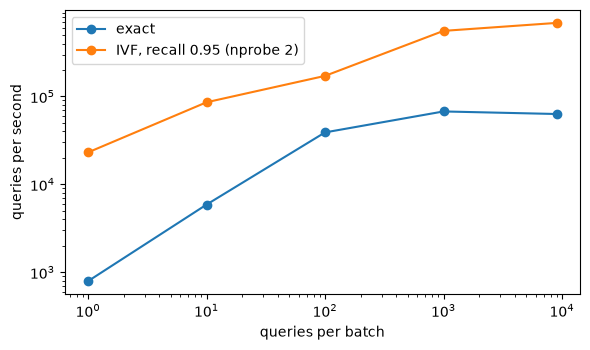

In [14]:
def rate(fn, b):
    q = rest[:b]
    fn(q)                                              # warm-up: copies, kernels for this shape
    calls = max(1, 2000 // b) if b < 1000 else 3
    start = time.perf_counter()
    for c in range(calls):
        fn(rest[c:c + 1] if b == 1 else q)
    return calls * b / (time.perf_counter() - start)


sizes = [1, 10, 100, 1000, 9000]
exact_rate = [rate(lambda q: truth_index.search(q, 10), b) for b in sizes]
approx_rate = [rate(lambda q: approx.search(q, 10), b) for b in sizes]
fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(sizes, exact_rate, marker="o", label="exact")
ax.plot(sizes, approx_rate, marker="o", label=f"IVF, recall 0.95 (nprobe {approx.nprobe})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("queries per batch"); ax.set_ylabel("queries per second"); ax.legend()
fig.tight_layout()

nprobe trades recall for speed. Below, recall against queries per second for a batch of 9,000 queries at
nprobe from 1 to 128 (`search(..., nprobe=)` overrides the calibrated value). Each step doubles the lists
scanned: recall climbs towards 1.0 and speed falls towards exact search's (in red, the dashed line its
speed). The calibrated nprobe is ringed: the fewest lists that reach the target.

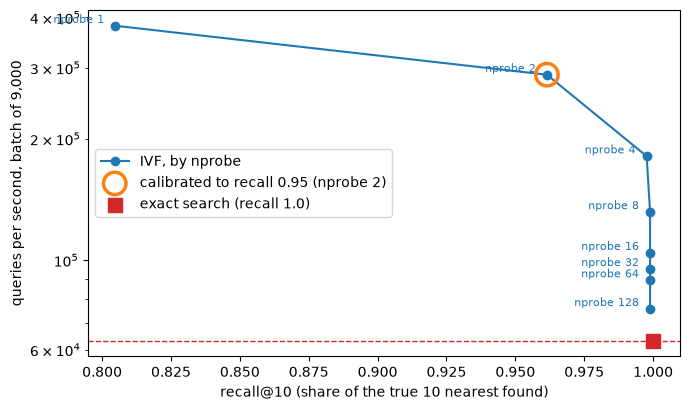

In [15]:
curve = []
for p in (1, 2, 4, 8, 16, 32, 64, 128):
    approx.search(rest, 10, nprobe=p)
    start = time.perf_counter()
    found = approx.search(rest, 10, nprobe=p).indices
    curve.append((recall(found, truth[1000:]), len(rest) / (time.perf_counter() - start), p))
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot([r for r, _, _ in curve], [q for _, q, _ in curve], marker="o", c="tab:blue", label="IVF, by nprobe")
for r, q, p in curve:
    ax.annotate(f"nprobe {p}", (r, q), textcoords="offset points", xytext=(-8, 2), ha="right", fontsize=8,
                color="tab:blue")
calibrated = [c for c in curve if c[2] == approx.nprobe]
if calibrated:
    ax.scatter([calibrated[0][0]], [calibrated[0][1]], s=260, facecolors="none", edgecolors="tab:orange",
               linewidths=2.5, zorder=3, label=f"calibrated to recall 0.95 (nprobe {approx.nprobe})")
ax.axhline(exact_rate[-1], color="tab:red", linestyle="--", linewidth=1)
ax.scatter([1.0], [exact_rate[-1]], marker="s", s=90, c="tab:red", zorder=3, label="exact search (recall 1.0)")
ax.set_yscale("log"); ax.set_xlabel("recall@10 (share of the true 10 nearest found)")
ax.set_ylabel("queries per second, batch of 9,000")
ax.legend(loc="center left"); fig.tight_layout()

**Calibrating on your queries (optional).** Without `calibration_queries`, siann calibrates on a sample of
the index's own vectors, and the target holds for queries like them. Here the queries are drawn like the
base vectors, so the two agree:

In [16]:
own = siann.Index(xb, "l2", recall=0.95)
print(f"calibrated on its own vectors: nprobe {own.nprobe}, recall {recall(own.search(rest, 10).indices, truth[1000:]):.3f}")
print(f"calibrated on 1,000 queries:   nprobe {approx.nprobe}, recall {recall(approx.search(rest, 10).indices, truth[1000:]):.3f}")

calibrated on its own vectors: nprobe 2, recall 0.961
calibrated on 1,000 queries:   nprobe 2, recall 0.961


On real data the queries often differ from the base vectors, in either direction, and calibrating on 1,000
of them pays on each dataset measured (a million vectors, target 0.95, recall on the other 9,000 queries;
BENCHMARKS.md, "Approximate search through siann.Index"):

| Dataset | Calibrated on its own vectors | Calibrated on 1,000 queries |
| --- | --- | --- |
| SIFT1M, L2 | nprobe 38, recall **0.940**: below the target | nprobe 46, recall 0.955 |
| Music-100, inner product | nprobe 129, recall 0.986; 60,076 / 170,253 queries/s in batches of 100 / 10,000 | nprobe 25, recall 0.946; 168,543 / 333,396 queries/s (**2.8x / 2.0x**) |

SIFT's queries are harder than its base vectors, so calibrating on them is what keeps the target, for 5-10%
of the speed. Music-100's are easier, so calibrating on them avoids scanning five times the lists needed,
and lands within 0.005 of the target. The same queries time the routing too: timed on its own vectors, Music-100's index sends
batches of 512 to a scan that runs at 0.77 times the speed of the other on real queries.

## Saving and loading an index

`index.save(path)` writes everything the index built: the vectors, the IVF's lists, the calibration and
its sample, the routes and the profile. `siann.Index.load(path)` reads it back without rebuilding, and
returns the same neighbors. On another machine it keeps the calibration, which depends only on the data,
and re-measures the routes, which depend on the machine; the plan says which it did.

In [17]:
import os
import tempfile

path = os.path.join(tempfile.mkdtemp(), "approx.siann")
start = time.perf_counter()
approx.save(path)
loaded = siann.Index.load(path)
print(f"saved and loaded in {time.perf_counter() - start:.2f} s ({os.path.getsize(path) / 1e6:.0f} MB)")
print(loaded.plan)
assert (loaded.search(rest, 10).indices == approx.search(rest, 10).indices).all()

saved and loaded in 0.06 s (105 MB)
siann.Index: 200,000 vectors, 128 dimensions, metric l2
  kind: ivf
  device: auto
  loaded from approx.siann, saved by siann 0.2.0 on 2026-11-22 on this machine
  approximate search: an IVF of 1,789 lists (about 4 sqrt(n)), built in 0.5 s (siann's k-means, 10 iterations)
  lists stored as float16 on the GPU (recall moves by at most about 0.001) and float32 on the CPU
  calibrated: nprobe 2 reaches recall@10 0.958 (target 0.95) on 1,000 of the given calibration queries
  IVF chosen: 1.9 ms for 1,000 calibration queries on the GPU, against 12.9 ms for exact search
  routing as saved, measured on this machine: below 65 queries on the CPU (single queries split over 4 threads); on the GPU query-major up to 4,096 queries, list-major from 4,097
  GPU found: approximate searches routed as above


## Changing an index

`index.add(x)` adds vectors and returns their ids; `index.remove(ids)` removes vectors by id. Searches return
ids: a vector's row number unless `add(x, ids=...)` names it. Added vectors are searched exactly until
10,000 of them (or 1% of the index) have gathered; then they are merged into the index, and an approximate
index recalibrates nprobe, so that the recall target keeps holding. Here, an index built on the first
150,000 vectors gets the other 50,000 in batches of 10,000. Their ids continue from 150,000, which are
their row numbers in `xb`, so the true neighbors from above still apply.

In [18]:
growing = siann.Index(xb[:150_000], "l2", recall=0.95, calibration_queries=xq[:1000])
for s in range(150_000, 200_000, 10_000):
    ids = growing.add(xb[s:s + 10_000])
print(f"ids of the last batch: {ids[0]:,} to {ids[-1]:,}; the index holds {growing.n:,}")
found = growing.search(rest, 10).indices
print(f"recall@10 on the other {len(rest):,} queries: {recall(found, truth[1000:]):.3f}")
print(growing.plan)

ids of the last batch: 190,000 to 199,999; the index holds 200,000
recall@10 on the other 9,000 queries: 0.977
siann.Index: 200,000 vectors, 128 dimensions, metric l2
  kind: ivf
  device: auto
  approximate search: an IVF of 1,549 lists (about 4 sqrt(n)), built in 0.4 s (siann's k-means, 10 iterations)
  lists stored as float16 on the GPU (recall moves by at most about 0.001) and float32 on the CPU
  calibrated: nprobe 2 reaches recall@10 0.978 (target 0.95) on 1,000 of the given calibration queries
  IVF chosen: 3.2 ms for 1,000 calibration queries on the GPU, against 10.3 ms for exact search
  routing measured in 0.8 s: below 65 queries on the CPU (single queries split over 4 threads); on the GPU query-major up to 4,096 queries, list-major from 4,097
  changed since built: 50,000 added, 0 removed
  merged 5 time(s); at the last, the buffer reached 10,000 vectors; nprobe recalibrated
  GPU found: approximate searches routed as above


Adding to an approximate index puts each vector in the list of its nearest centroid, and the centroids stay
as they were. That keeps recall, but vectors from regions the centroids never saw crowd into a few lists,
which slows searches. When the largest list has doubled against the mean since the index was clustered, or
the index has doubled in size, siann clusters it again (in the `add` that crosses the line), and the plan
says why. Here, 30,000 vectors from 20 new centres:

In [19]:
new_centers = 3 + rng.standard_normal((20, 128), dtype=np.float32)
elsewhere = (new_centers[rng.integers(0, 20, 30_000)]
             + 0.3 * rng.standard_normal((30_000, 128), dtype=np.float32))
start = time.perf_counter()
for s in range(0, 30_000, 10_000):
    growing.add(elsewhere[s:s + 10_000])
print(f"added in {time.perf_counter() - start:.1f} s")
print("\n".join(line for line in str(growing.plan).splitlines() if "merged" in line or "clustered" in line))

added in 1.6 s
  approximate search: an IVF of 1,833 lists (about 4 sqrt(n)), re-clustered in 0.5 s (siann's k-means, 10 iterations)
  merged 8 time(s); at the last, the buffer reached 10,000 vectors; nprobe recalibrated
  re-clustered 1 time(s); the last as its largest list reached 36.2 times the mean, against 9.4 when clustered: 1,833 lists in 0.5 s


Removed vectors are never returned, and the results stay exact. Vectors added with ids of your own are found
by them:

In [20]:
near = growing.search(xq[:1], 3).indices[0]
growing.remove(near)
print(f"removed {near}; the nearest now: {growing.search(xq[:1], 3).indices[0]}")
mine = growing.add(xq[:2], ids=[10**9, 10**9 + 1])
print(f"added with ids {mine}: the nearest to the first query is {growing.search(xq[:1], 1).indices[0, 0]:,}")

removed [ 99292  32881 181940]; the nearest now: [ 30736 141620  95006]
added with ids [1000000000 1000000001]: the nearest to the first query is 1,000,000,000


`index.recluster()` clusters the index again when you choose, and `index.save()` merges and compacts first
and keeps the ids.

## When fewer than k exist

Asking for more neighbors than there are vectors returns all of them, then `-1` in the missing slots, with
the metric's worst score (infinity for a distance, minus infinity for a similarity). A neighbor is never
made up.

In [21]:
small = siann.Index(xb[:3], "l2")
small.search(xq[:1], k=5)

SearchResult(indices=array([[ 1,  2,  0, -1, -1]]), scores=array([[15.446122, 16.946627, 17.480204,       inf,       inf]],
      dtype=float32))

## What siann refuses

siann searches dense vectors, so a sparse matrix is refused with an explanation rather than converted
silently.

In [22]:
import scipy.sparse

try:
    siann.Index(scipy.sparse.random(100, 20, density=0.1, format="csr"), "ip")
except NotImplementedError as e:
    print("NotImplementedError:", e)

NotImplementedError: xb is a sparse matrix: siann searches dense vectors; pass a NumPy array (x.toarray() for a small one)
